In [1]:
%load_ext autoreload
%autoreload 2
import os, sys
os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'

In [ ]:
# ------------------------RUN THIS BLOCK ONLY IF YOU ARE RUNNING IN GOOGLE COLAB------------------------
# ! git clone https://github.com/akarshkumar0101/fer.git
# %cd fer/src
# ! pip install "evosax==0.1.6"

In [2]:
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from einops import rearrange, repeat

import jax
import jax.numpy as jnp

from cppn import CPPN, FlattenCPPNParameters
from cppn_modified import CPPN as mCPPN, FlattenCPPNParameters as mFlattenCPPNParameters
import util

## Preprocessing the Picbreeder Genomes

Run these commands to preprocess the genomes from Picbreeder.
This involves loading the raw genome data, interpreting it as a NEAT computation graph, and then layerizing it into an Flax (Jax) MLP, as described in the paper.
Layerization means porting it into a dense MLP format, ameniable to SGD

NOTE: you do not have to run this if you don't want to, we have already put the data in this repo.

In [4]:
! python process_pb.py --zip_path="../picbreeder_genomes/skull.zip"  --save_dir="../data/picbreeder_skull"
! python process_pb.py --zip_path="../picbreeder_genomes/butterfly.zip"  --save_dir="../data/picbreeder_butterfly"
! python process_pb.py --zip_path="../picbreeder_genomes/apple.zip"  --save_dir="../data/picbreeder_apple"

ParameterReshaper: 5478 parameters detected for optimization.
ParameterReshaper: 5478 parameters detected for optimization.
ParameterReshaper: 8096 parameters detected for optimization.
ParameterReshaper: 8096 parameters detected for optimization.
ParameterReshaper: 46474 parameters detected for optimization.
ParameterReshaper: 46474 parameters detected for optimization.


Great! Let's take a look at the outputs of the CPPNs.

## Original

genome: skull, arch: 12;cache:15,gaussian:4,identity:2,sin:1
ParameterReshaper: 5478 parameters detected for optimization.
genome: butterfly, arch: 16;cache:17,gaussian:4,sigmoid:1,sin:1
ParameterReshaper: 8096 parameters detected for optimization.
genome: apple, arch: 33;cache:28,gaussian:3,sigmoid:5,sin:2
ParameterReshaper: 46474 parameters detected for optimization.


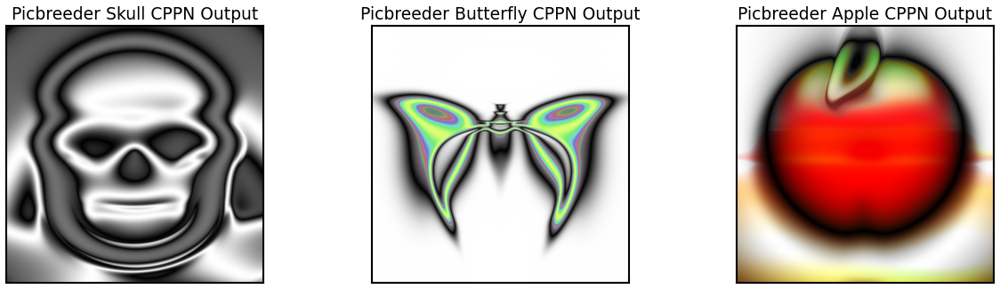

In [4]:
plt.figure(figsize=(20, 5), dpi=75)
iplt = 0
for genome in ["skull", "butterfly", "apple"]:
    iplt += 1
    plt.subplot(1, 3, iplt)
    save_dir = f"../data/picbreeder_{genome}"
    arch_ = util.load_pkl(save_dir, "arch")
    print(f"genome: {genome}, arch: {arch_}")
    params = util.load_pkl(save_dir, "params")
    cppn = FlattenCPPNParameters(CPPN(arch_))
    img = np.array(cppn.generate_image(params, img_size=512))
    plt.imshow(img); plt.xticks([]); plt.yticks([]); plt.grid(False)
    plt.title(f"Picbreeder {genome.capitalize()} CPPN Output", fontsize=18)
    for spine in plt.gca().spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(2)
plt.show()

## Modified

genome: skull, arch: 12;cache:15,gaussian:4,identity:2,sin:1
ParameterReshaper: 5478 parameters detected for optimization.
genome: butterfly, arch: 16;cache:17,gaussian:4,sigmoid:1,sin:1
ParameterReshaper: 8096 parameters detected for optimization.
genome: apple, arch: 33;cache:28,gaussian:3,sigmoid:5,sin:2
ParameterReshaper: 46474 parameters detected for optimization.


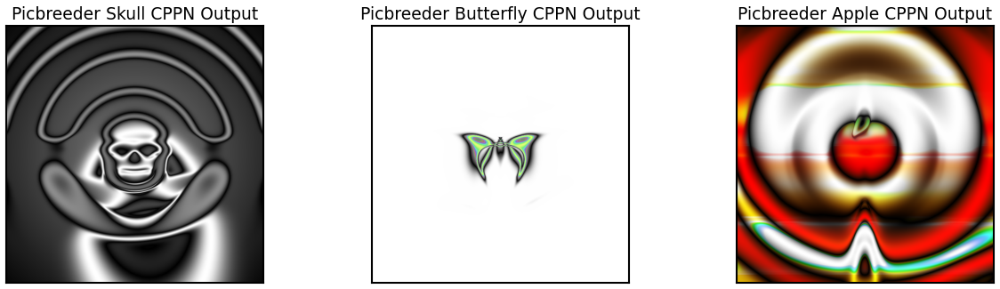

In [7]:
PAD = 256

plt.figure(figsize=(20, 5), dpi=75)
iplt = 0
for genome in ["skull", "butterfly", "apple"]:
    iplt += 1
    plt.subplot(1, 3, iplt)
    save_dir = f"../data/picbreeder_{genome}"
    arch_ = util.load_pkl(save_dir, "arch")
    print(f"genome: {genome}, arch: {arch_}")
    params = util.load_pkl(save_dir, "params")
    cppn = mFlattenCPPNParameters(mCPPN(arch_))
    img = np.array(cppn.generate_image(params, img_size=256, pad_pixels=PAD))

    destination = f"../data/{genome}_modified.png"
    plt.imsave(destination, img)
    
    plt.imshow(img); plt.xticks([]); plt.yticks([]); plt.grid(False)
    plt.title(f"Picbreeder {genome.capitalize()} CPPN Output", fontsize=18)
    for spine in plt.gca().spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(2)
plt.show()

## Training SGD CPPNs to Copy Behavior

Now, run these commands to run SGD on CPPNs with the same architecture to mimic the output behavior.
We are training to match the Picbreeder output images using an MSE loss.

NOTE: you do not have to run this if you don't want to, we have already put the data in this repo.

In [ ]:
! python train_sgd.py --seed=2 --save_dir="../data/sgd_skull" --arch="12;cache:15,gaussian:4,identity:2,sin:1" --img_file="../data/picbreeder_skull/img.png" --n_iters=100000 --lr=0.003 
! python train_sgd.py --seed=0 --save_dir="../data/sgd_butterfly" --arch="16;cache:17,gaussian:4,sigmoid:1,sin:1" --img_file="../data/picbreeder_butterfly/img.png" --n_iters=100000 --lr=0.003 
! python train_sgd.py --seed=0 --save_dir="../data/sgd_apple" --arch="33;cache:28,gaussian:3,sigmoid:5,sin:2" --img_file="../data/picbreeder_apple/img.png" --n_iters=100000 --lr=0.0003 # needs lower lr

Let's take a look at the loss curves!

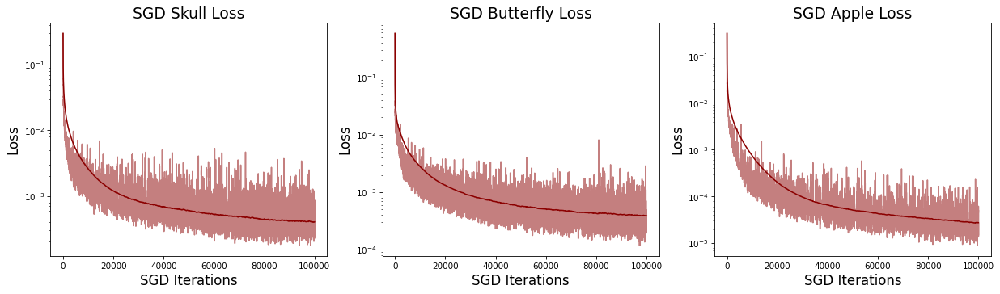

In [6]:
plt.figure(figsize=(20, 5), dpi=75)
iplt = 0
for genome in ["skull", "butterfly", "apple"]:
    iplt += 1
    plt.subplot(1, 3, iplt)
    save_dir = f"../data/sgd_{genome}"
    losses = util.load_pkl(save_dir, "losses")
    plt.plot(losses, c='darkred', alpha=0.5)
    losses_smoothed = pd.Series(losses).ewm(span=10000).mean()
    plt.plot(losses_smoothed, c='darkred')
    plt.yscale('log')
    plt.title(f"SGD {genome.capitalize()} Loss", fontsize=18)
    plt.xlabel("SGD Iterations", fontsize=16); plt.ylabel("Loss", fontsize=16)
plt.show()


Looks good! Now, let's take a look at the outputs of the SGD CPPNs.

## Original

ParameterReshaper: 5478 parameters detected for optimization.
ParameterReshaper: 8096 parameters detected for optimization.
ParameterReshaper: 46474 parameters detected for optimization.


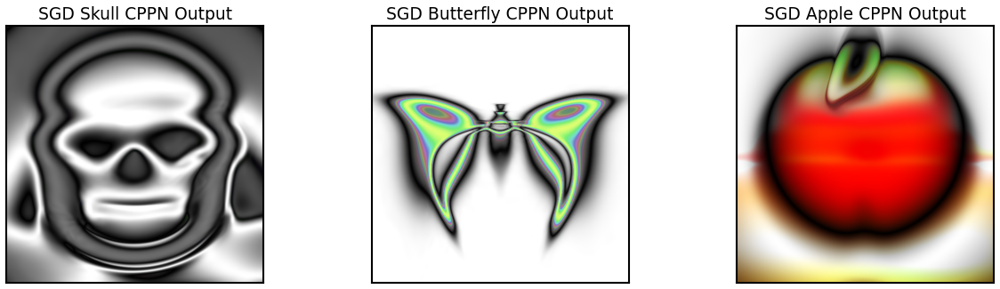

In [9]:
plt.figure(figsize=(20, 5), dpi=75)
iplt = 0
for genome in ["skull", "butterfly", "apple"]:
    iplt += 1
    plt.subplot(1, 3, iplt)
    save_dir = f"../data/sgd_{genome}"
    arch_ = util.load_pkl(save_dir, "arch")
    params = util.load_pkl(save_dir, "params")
    cppn = FlattenCPPNParameters(CPPN(arch_))
    img = np.array(cppn.generate_image(params, img_size=512))
    plt.imshow(img); plt.xticks([]); plt.yticks([]); plt.grid(False)
    plt.title(f"SGD {genome.capitalize()} CPPN Output", fontsize=18)
    for spine in plt.gca().spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(2)
plt.show()

## Modified

ParameterReshaper: 46474 parameters detected for optimization.
ParameterReshaper: 46474 parameters detected for optimization.
ParameterReshaper: 46474 parameters detected for optimization.
ParameterReshaper: 46474 parameters detected for optimization.
ParameterReshaper: 46474 parameters detected for optimization.
ParameterReshaper: 46474 parameters detected for optimization.


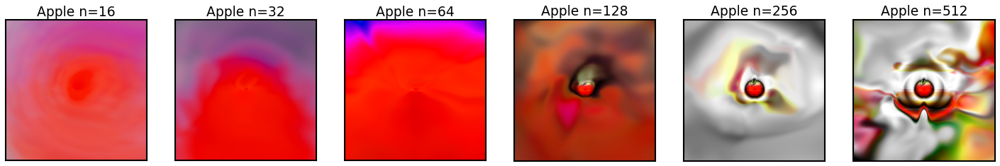

In [6]:
import os

total_size = 512 * 3
base_size = 256   # mesmo --base_size do treino: passo entre pixels = 2/(base_size-1)
genome = 'apple'
sizes = ["0016", "0032", "0064", "0128", "0256", "0512"]#, "1024"]
sizes = [s for s in sizes if os.path.isdir(f"../data/varying_sizes/{genome}/n{s}")]

# Mesma grade da célula de erro: base_size + 2*pad = total_size (pad é POR LADO).
pad = (total_size - base_size) // 2
assert base_size + 2 * pad == total_size

def gen(cppn, params):
    return np.array(cppn.generate_image(params, img_size=base_size, pad_pixels=pad))

plt.figure(figsize=(4 * len(sizes), 5), dpi=75)
for iplt, size in enumerate(sizes, start=1):
    plt.subplot(1, len(sizes), iplt)
    n = int(size)

    save_dir = f"../data/varying_sizes/{genome}/n{size}"
    arch_ = util.load_pkl(save_dir, "arch")
    params = util.load_pkl(save_dir, "params")
    cppn = mFlattenCPPNParameters(mCPPN(arch_))
    img = gen(cppn, params)

    # uint8 ocupa 4x menos que float32; o imshow guarda uma referência a cada imagem
    img = (np.clip(img, 0, 1) * 255).astype(np.uint8)

    #destination = f"../data/{genome}_sgd_n{size}.png"
    #plt.imsave(destination, img)

    plt.imshow(img); plt.xticks([]); plt.yticks([]); plt.grid(False)
    plt.title(f"{genome.capitalize()} n={n}", fontsize=18)
    for spine in plt.gca().spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(2)
plt.show()

# Modified with local margin

ParameterReshaper: 46474 parameters detected for optimization.
ParameterReshaper: 46474 parameters detected for optimization.
ParameterReshaper: 46474 parameters detected for optimization.
ParameterReshaper: 46474 parameters detected for optimization.
ParameterReshaper: 46474 parameters detected for optimization.
ParameterReshaper: 46474 parameters detected for optimization.


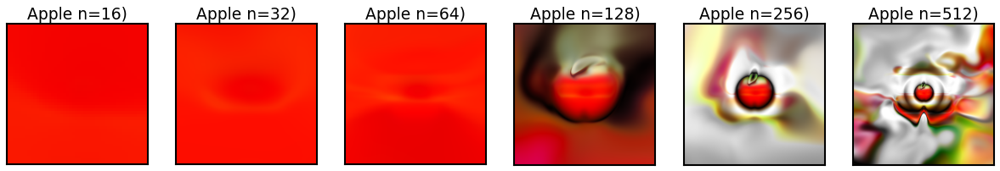

In [ ]:
BASE_SIZE = 256  # passo entre pixels = 2/(BASE_SIZE-1), o mesmo do treino
genome = "apple"
sizes = ["0016", "0032", "0064", "0128", "0256", "0512"]#, "1024"]

def generate_with_margin(cppn, params, n):
    """Centro de treino n x n + margem n de cada lado = imagem 3n x 3n, com passo fixo.
    generate_image com img_size=BASE_SIZE fixa o passo; o tamanho 3n sai de pad_pixels
    (por lado) e, se 3n < BASE_SIZE, de um recorte central."""
    total = 3 * n
    G = max(BASE_SIZE, total)
    pad = (G - BASE_SIZE) // 2
    img = np.array(cppn.generate_image(params, img_size=BASE_SIZE, pad_pixels=pad))
    off = (G - total) // 2
    return img[off:off + total, off:off + total]

plt.figure(figsize=(20, 5), dpi=75)
for iplt, size in enumerate(sizes, start=1):
    plt.subplot(1, len(sizes), iplt)
    n = int(size)
    save_dir = f"../data/varying_sizes/{genome}/n{size}"
    arch_ = util.load_pkl(save_dir, "arch")
    params = util.load_pkl(save_dir, "params")
    cppn = mFlattenCPPNParameters(mCPPN(arch_))
    img = generate_with_margin(cppn, params, n)

    #destination = f"../data/{genome}_sgd_n{size}.png"
    #plt.imsave(destination, np.clip(img, 0, 1))

    plt.imshow(img); plt.xticks([]); plt.yticks([]); plt.grid(False)
    plt.title(f"{genome.capitalize()} n={n})", fontsize=18)
    for spine in plt.gca().spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(2)
plt.show()

# Modified Single Image

In [ ]:
IMG_SIZE = 1024

plt.figure(figsize=(20, 5), dpi=75)
genome = 'apple'
plt.subplot(1, 1, 1)
save_dir = f"../data/varying_sizes/{genome}/n0032"
arch_ = util.load_pkl(save_dir, "arch")
params = util.load_pkl(save_dir, "params")
cppn = mFlattenCPPNParameters(mCPPN(arch_))
img = np.array(cppn.generate_image(params, img_size=IMG_SIZE, pad_pixels=IMG_SIZE))

#destination = f"../data/{genome}_sgd_modified.png"
#plt.imsave(destination, img)

plt.imshow(img); plt.xticks([]); plt.yticks([]); plt.grid(False)
plt.title(f"SGD {genome.capitalize()} CPPN Output", fontsize=18)
for spine in plt.gca().spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(2)
plt.show()

ParameterReshaper: 46474 parameters detected for optimization.


# Error measure between networks

## Original


ParameterReshaper: 5478 parameters detected for optimization.
ParameterReshaper: 5478 parameters detected for optimization.


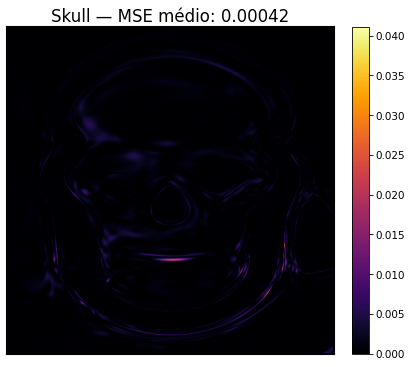

Erro médio (MSE) por genoma:
  skull: 0.000422


In [5]:
img_size = 512 

plt.figure(figsize=(20, 5), dpi=75)
mean_errors = {}

genome = 'skull'
plt.subplot(1, 3, 1)

# --- imagem original (Picbreeder) ---
save_dir_orig = f"../data/picbreeder_{genome}"
arch_orig = util.load_pkl(save_dir_orig, "arch")
params_orig = util.load_pkl(save_dir_orig, "params")
cppn_orig = FlattenCPPNParameters(CPPN(arch_orig))
img_orig = np.array(cppn_orig.generate_image(params_orig, img_size=img_size))

# --- imagem reproduzida via SGD ---
save_dir_sgd = f"../data/sgd_{genome}"
arch_sgd = util.load_pkl(save_dir_sgd, "arch")
params_sgd = util.load_pkl(save_dir_sgd, "params")
cppn_sgd = FlattenCPPNParameters(CPPN(arch_sgd))
img_sgd = np.array(cppn_sgd.generate_image(params_sgd, img_size=img_size))

# --- erro por pixel: MSE, média sobre os canais RGB ---
error_map = ((img_orig - img_sgd) ** 2).mean(axis=-1)  # shape: (img_size, img_size)
mean_error = error_map.mean()
mean_errors[genome] = mean_error

im = plt.imshow(error_map, cmap='inferno')
plt.xticks([]); plt.yticks([]); plt.grid(False)
plt.title(f"{genome.capitalize()} — MSE médio: {mean_error:.5f}", fontsize=16)
plt.colorbar(im, fraction=0.046, pad=0.04)

for spine in plt.gca().spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(2)

plt.tight_layout()
plt.show()

print("Erro médio (MSE) por genoma:")
for genome, err in mean_errors.items():
    print(f"  {genome}: {err:.6f}")

## Modified


ParameterReshaper: 46474 parameters detected for optimization.
ParameterReshaper: 46474 parameters detected for optimization.
ParameterReshaper: 46474 parameters detected for optimization.
ParameterReshaper: 46474 parameters detected for optimization.
ParameterReshaper: 46474 parameters detected for optimization.
ParameterReshaper: 46474 parameters detected for optimization.
ParameterReshaper: 46474 parameters detected for optimization.


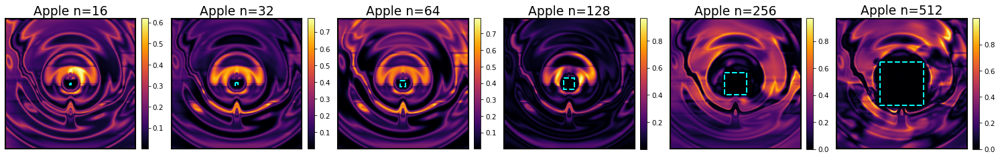

Erro médio (MSE, apenas margem) por tamanho de treino — apple:
  n=0016: 0.155481
  n=0032: 0.155101
  n=0064: 0.193434
  n=0128: 0.116408
  n=0256: 0.250737
  n=0512: 0.242176


In [7]:
total_size = 512 * 3
base_size = 256   # mesmo --base_size do treino: passo entre pixels = 2/(base_size-1)
genome = 'apple'
sizes = ["0016", "0032", "0064", "0128", "0256", "0512"]#, "1024"]

# Grade de avaliação comum (total_size x total_size), centrada na origem e com o
# mesmo passo usado no treino. pad_pixels é POR LADO: o resultado tem
# base_size + 2*pad pixels (era isso que dava 3056 no erro).
pad = (total_size - base_size) // 2
assert base_size + 2 * pad == total_size

def gen(cppn, params):
    return np.array(cppn.generate_image(params, img_size=base_size, pad_pixels=pad))

# --- imagem original (Picbreeder): não depende de n, gera uma vez só ---
save_dir_orig = f"../data/picbreeder_{genome}"
arch_orig = util.load_pkl(save_dir_orig, "arch")
params_orig = util.load_pkl(save_dir_orig, "params")
cppn_orig = mFlattenCPPNParameters(mCPPN(arch_orig))
img_orig = gen(cppn_orig, params_orig)

idx = np.arange(total_size)
ii, jj = np.meshgrid(idx, idx, indexing='ij')

plt.figure(figsize=(20, 5), dpi=75)
mean_errors = {}

for iplt, size in enumerate(sizes, start=1):
    plt.subplot(1, len(sizes), iplt)

    n = int(size)
    off = (total_size - n) // 2  # canto superior esquerdo do centro de treino n x n

    # máscara: True = margem (fora do conjunto de treino), False = centro de treino
    margin_mask = ~(
        (ii >= off) & (ii < off + n) &
        (jj >= off) & (jj < off + n)
    )

    # --- imagem reproduzida via SGD ---
    save_dir_sgd = f"../data/varying_sizes/{genome}/n{size}"
    arch_sgd = util.load_pkl(save_dir_sgd, "arch")
    params_sgd = util.load_pkl(save_dir_sgd, "params")
    cppn_sgd = mFlattenCPPNParameters(mCPPN(arch_sgd))
    img_sgd = gen(cppn_sgd, params_sgd)

    # --- erro por pixel: MSE, média sobre os canais RGB ---
    error_map = ((img_orig - img_sgd) ** 2).mean(axis=-1)  # (total_size, total_size)
    mean_error = error_map[margin_mask].mean()             # só a margem
    mean_errors[size] = mean_error

    im = plt.imshow(error_map, cmap='inferno')
    plt.xticks([]); plt.yticks([]); plt.grid(False)
    plt.title(f"{genome.capitalize()} n={n}", fontsize=18)
    plt.colorbar(im, fraction=0.046, pad=0.04)

    # marca a região de treino (excluída do cálculo)
    rect = plt.Rectangle((off, off), n, n, fill=False,
                         edgecolor='cyan', linewidth=2, linestyle='--')
    plt.gca().add_patch(rect)

    for spine in plt.gca().spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(2)

plt.tight_layout()
plt.show()

print(f"Erro médio (MSE, apenas margem) por tamanho de treino — {genome}:")
for size, err in mean_errors.items():
    print(f"  n={size}: {err:.6f}")

# Modified own dimensions

ParameterReshaper: 46474 parameters detected for optimization.
ParameterReshaper: 46474 parameters detected for optimization.
ParameterReshaper: 46474 parameters detected for optimization.
ParameterReshaper: 46474 parameters detected for optimization.
ParameterReshaper: 46474 parameters detected for optimization.
ParameterReshaper: 46474 parameters detected for optimization.
ParameterReshaper: 46474 parameters detected for optimization.


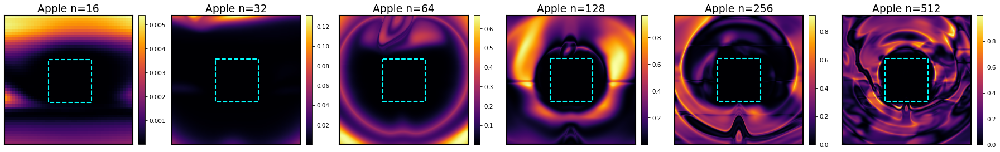

MSE por rede, imagem completa 3n x 3n (padding = n) — apple:
       n |  treino (centro) |   teste (margem)
    0016 |         0.000004 |         0.001396
    0032 |         0.000003 |         0.007992
    0064 |         0.000127 |         0.146076
    0128 |         0.000019 |         0.303765
    0256 |         0.000053 |         0.209106
    0512 |         0.000238 |         0.242176


In [5]:
import os

base_size = 256   # mesmo --base_size do treino: passo entre pixels = 2/(base_size-1)
genome = 'apple'
sizes = ["0016", "0032", "0064", "0128", "0256", "0512"]#, "1024"]

sizes = [s for s in sizes if os.path.isdir(f"../data/varying_sizes/{genome}/n{s}")]
max_total = 3 * max(int(s) for s in sizes)

def center_crop(img, size):
    off = (img.shape[0] - size) // 2
    return img[off:off + size, off:off + size]

def gen_window(cppn, params, size):
    """Imagem size x size centrada na origem, com passo 2/(base_size-1).

    generate_image exige img_size=base_size (é ele que fixa o passo); o tamanho
    desejado é obtido com pad_pixels (por lado) e, se size < base_size, com um
    recorte central. As paridades batem porque base_size e size são pares.
    """
    G = max(base_size, size)
    pad = (G - base_size) // 2
    img = np.array(cppn.generate_image(params, img_size=base_size, pad_pixels=pad))
    return center_crop(img, size)

# --- imagem original (Picbreeder): gera uma vez no maior tamanho e recorta ---
save_dir_orig = f"../data/picbreeder_{genome}"
arch_orig = util.load_pkl(save_dir_orig, "arch")
params_orig = util.load_pkl(save_dir_orig, "params")
cppn_orig = mFlattenCPPNParameters(mCPPN(arch_orig))
img_orig_max = gen_window(cppn_orig, params_orig, max_total)

plt.figure(figsize=(4 * len(sizes), 5), dpi=75)
errors = {}

for iplt, size in enumerate(sizes, start=1):
    plt.subplot(1, len(sizes), iplt)
    n = int(size)
    total = 3 * n  # padding = n de cada lado

    # --- imagem reproduzida via SGD, no tamanho total 3n ---
    save_dir_sgd = f"../data/varying_sizes/{genome}/n{size}"
    arch_sgd = util.load_pkl(save_dir_sgd, "arch")
    params_sgd = util.load_pkl(save_dir_sgd, "params")
    cppn_sgd = mFlattenCPPNParameters(mCPPN(arch_sgd))
    img_sgd = gen_window(cppn_sgd, params_sgd, total)
    img_orig = center_crop(img_orig_max, total)

    # --- erro por pixel: MSE, média sobre os canais RGB ---
    error_map = ((img_orig - img_sgd) ** 2).mean(axis=-1)  # (3n, 3n)

    train_region = np.zeros((total, total), dtype=bool)
    train_region[n:2 * n, n:2 * n] = True
    train_mse = error_map[train_region].mean()    # centro n x n (treino)
    margin_mse = error_map[~train_region].mean()  # margem de largura n (teste)
    errors[size] = (train_mse, margin_mse)

    im = plt.imshow(error_map, cmap='inferno')
    plt.xticks([]); plt.yticks([]); plt.grid(False)
    plt.title(f"{genome.capitalize()} n={n}", fontsize=18)
    plt.colorbar(im, fraction=0.046, pad=0.04)

    # contorno da região de treino
    rect = plt.Rectangle((n, n), n, n, fill=False,
                         edgecolor='cyan', linewidth=2, linestyle='--')
    plt.gca().add_patch(rect)

    for spine in plt.gca().spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(2)

plt.tight_layout()
plt.show()

print(f"MSE por rede, imagem completa 3n x 3n (padding = n) — {genome}:")
print(f"  {'n':>6} | {'treino (centro)':>16} | {'teste (margem)':>16}")
for size, (tr, te) in errors.items():
    print(f"  {size:>6} | {tr:16.6f} | {te:16.6f}")

ParameterReshaper: 5478 parameters detected for optimization.
ParameterReshaper: 5478 parameters detected for optimization.


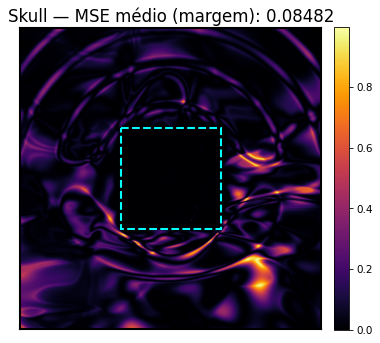

Erro médio (MSE, apenas margem) por genoma:
  skull: 0.084824


In [13]:
## INDIVIDUAL RETREINADO

img_size = 256
PAD = 256
total_size = img_size + 2 * PAD  # 1536

plt.figure(figsize=(5, 5), dpi=75)
mean_errors = {}

# --- máscara geométrica: True = margem (fora do domínio original), False = centro original ---
idx = np.arange(total_size)
ii, jj = np.meshgrid(idx, idx, indexing='ij')
margin_mask = ~(
    (ii >= PAD) & (ii < PAD + img_size) &
    (jj >= PAD) & (jj < PAD + img_size)
)

for iplt, genome in enumerate(["skull"], start=1):
    plt.subplot(1, 1, iplt)

    # --- imagem original (Picbreeder) ---
    save_dir_orig = f"../data/picbreeder_{genome}"
    arch_orig = util.load_pkl(save_dir_orig, "arch")
    params_orig = util.load_pkl(save_dir_orig, "params")
    cppn_orig = mFlattenCPPNParameters(mCPPN(arch_orig))
    img_orig = np.array(cppn_orig.generate_image(params_orig, img_size=img_size, pad_pixels=PAD))

    # --- imagem reproduzida via SGD ---
    save_dir_sgd = f"../data/sgd_validation_results/{genome}"
    arch_sgd = util.load_pkl(save_dir_sgd, "arch")
    params_sgd = util.load_pkl(save_dir_sgd, "params_best")
    cppn_sgd = mFlattenCPPNParameters(mCPPN(arch_sgd))
    img_sgd = np.array(cppn_sgd.generate_image(params_sgd, img_size=img_size, pad_pixels=PAD))

    # --- erro por pixel: MSE, média sobre os canais RGB ---
    error_map = ((img_orig - img_sgd) ** 2).mean(axis=-1)  # shape: (total_size, total_size)
    mean_error = error_map[margin_mask].mean()  # só a margem, exclui o centro img_size x img_size
    mean_errors[genome] = mean_error

    im = plt.imshow(error_map, cmap='inferno')
    plt.xticks([]); plt.yticks([]); plt.grid(False)
    plt.title(f"{genome.capitalize()} — MSE médio (margem): {mean_error:.5f}", fontsize=16)
    plt.colorbar(im, fraction=0.046, pad=0.04)

    # opcional: marca visualmente a região excluída do cálculo
    rect = plt.Rectangle((PAD, PAD), img_size, img_size,
                         fill=False, edgecolor='cyan', linewidth=2, linestyle='--')
    plt.gca().add_patch(rect)

    for spine in plt.gca().spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(2)

plt.tight_layout()
plt.show()

print("Erro médio (MSE, apenas margem) por genoma:")
for genome, err in mean_errors.items():
    print(f"  {genome}: {err:.6f}")

### Mapa de erro dos três genomas

ParameterReshaper: 5478 parameters detected for optimization.
ParameterReshaper: 5478 parameters detected for optimization.
ParameterReshaper: 8096 parameters detected for optimization.
ParameterReshaper: 8096 parameters detected for optimization.
ParameterReshaper: 46474 parameters detected for optimization.
ParameterReshaper: 46474 parameters detected for optimization.


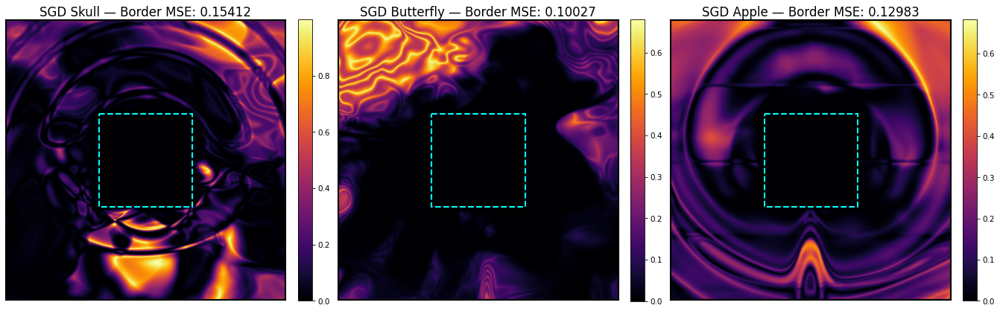

MSE por genoma (SGD original vs Picbreeder):
      genoma |     centro |     margem
       skull |   0.000421 |   0.154116
   butterfly |   0.000194 |   0.100267
       apple |   0.000048 |   0.129829


In [7]:
## SGD ORIGINAIS (sgd_{genome}) — mapa de erro com margem de 256 px

img_size = 256
PAD = 256
total_size = img_size + 2 * PAD  # 768

genomes = ["skull", "butterfly", "apple"]
plt.figure(figsize=(6 * len(genomes), 6), dpi=75)
mean_errors = {}

# --- máscara geométrica: True = margem (fora do domínio original), False = centro original ---
idx = np.arange(total_size)
ii, jj = np.meshgrid(idx, idx, indexing='ij')
margin_mask = ~(
    (ii >= PAD) & (ii < PAD + img_size) &
    (jj >= PAD) & (jj < PAD + img_size)
)

for iplt, genome in enumerate(genomes, start=1):
    plt.subplot(1, len(genomes), iplt)

    # --- imagem original (Picbreeder) ---
    save_dir_orig = f"../data/picbreeder_{genome}"
    arch_orig = util.load_pkl(save_dir_orig, "arch")
    params_orig = util.load_pkl(save_dir_orig, "params")
    cppn_orig = mFlattenCPPNParameters(mCPPN(arch_orig))
    img_orig = np.array(cppn_orig.generate_image(params_orig, img_size=img_size, pad_pixels=PAD))

    # --- imagem reproduzida via SGD (original, sem validação) ---
    save_dir_sgd = f"../data/sgd_{genome}"
    arch_sgd = util.load_pkl(save_dir_sgd, "arch")
    params_sgd = util.load_pkl(save_dir_sgd, "params")
    cppn_sgd = mFlattenCPPNParameters(mCPPN(arch_sgd))
    img_sgd = np.array(cppn_sgd.generate_image(params_sgd, img_size=img_size, pad_pixels=PAD))

    # --- erro por pixel: MSE, média sobre os canais RGB ---
    error_map = ((img_orig - img_sgd) ** 2).mean(axis=-1)  # (total_size, total_size)
    center_error = error_map[~margin_mask].mean()
    margin_error = error_map[margin_mask].mean()
    mean_errors[genome] = (center_error, margin_error)

    im = plt.imshow(error_map, cmap='inferno')
    plt.xticks([]); plt.yticks([]); plt.grid(False)
    plt.title(f"SGD {genome.capitalize()} — Border MSE: {margin_error:.5f}", fontsize=16)
    plt.colorbar(im, fraction=0.046, pad=0.04)

    # marca visualmente a região original (excluída do MSE da margem)
    rect = plt.Rectangle((PAD, PAD), img_size, img_size,
                         fill=False, edgecolor='cyan', linewidth=2, linestyle='--')
    plt.gca().add_patch(rect)

    for spine in plt.gca().spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(2)

plt.tight_layout()
plt.show()

print("MSE por genoma (SGD original vs Picbreeder):")
print(f"  {'genoma':>10} | {'centro':>10} | {'margem':>10}")
for genome, (c, m) in mean_errors.items():
    print(f"  {genome:>10} | {c:10.6f} | {m:10.6f}")


ParameterReshaper: 5478 parameters detected for optimization.
ParameterReshaper: 5478 parameters detected for optimization.


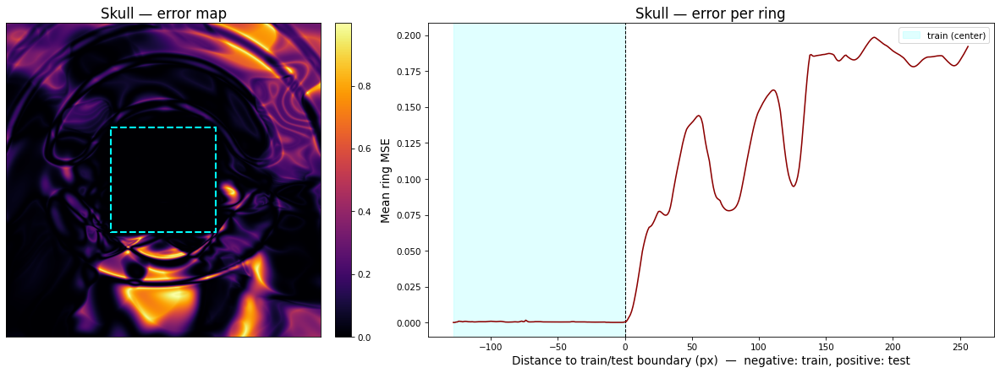

skull: MSE center = 0.000421 | MSE margin = 0.154116

Distance vs. error correlation (per-ring means) — skull:
          region | n rings | Pearson r |         p | Spearman ρ |         p
   test (margin) |     256 |    0.8522 |  2.02e-73 |     0.8176 |  7.68e-63
  train (center) |     128 |   -0.5598 |  6.42e-12 |    -0.6413 |  3.52e-16
     whole image |     384 |    0.9383 | 2.69e-178 |     0.8848 | 9.76e-129


In [14]:
## ERROR PER RING (distance to the train/test boundary) — single genome
from scipy.stats import pearsonr, spearmanr

genome = "skull"
img_size = 256
PAD = 256
total_size = img_size + 2 * PAD  # 768

save_dir_sgd = f"../data/sgd_{genome}"   # or f"../data/sgd_validation_results/{genome}"
params_name = "params"                   # or "params_best" for the retrained one

# --- original image (Picbreeder) ---
save_dir_orig = f"../data/picbreeder_{genome}"
arch_orig = util.load_pkl(save_dir_orig, "arch")
params_orig = util.load_pkl(save_dir_orig, "params")
cppn_orig = mFlattenCPPNParameters(mCPPN(arch_orig))
img_orig = np.array(cppn_orig.generate_image(params_orig, img_size=img_size, pad_pixels=PAD))

# --- SGD reproduction ---
arch_sgd = util.load_pkl(save_dir_sgd, "arch")
params_sgd = util.load_pkl(save_dir_sgd, params_name)
cppn_sgd = mFlattenCPPNParameters(mCPPN(arch_sgd))
img_sgd = np.array(cppn_sgd.generate_image(params_sgd, img_size=img_size, pad_pixels=PAD))

# --- per-pixel error: MSE averaged over RGB channels (values in [0, 1]) ---
error_map = ((img_orig - img_sgd) ** 2).mean(axis=-1)  # (total_size, total_size)

# --- ring of each pixel: Chebyshev (square) distance to the boundary ---
# Training region = pixels [PAD, PAD + img_size - 1] on each axis.
# d_axis > 0: outside the interval on that axis; d_axis <= 0: inside (= -distance to the edge).
idx = np.arange(total_size)
lo, hi = PAD, PAD + img_size - 1
d_axis = np.maximum(lo - idx, idx - hi)
d = np.maximum(d_axis[:, None], d_axis[None, :])
# Rings: test (margin)   = +1, +2, ..., +PAD          (+1 = first ring outside the boundary)
#        train (center)  = -1, -2, ..., -img_size/2   (-1 = last ring inside the boundary)
ring = np.where(d > 0, d, d - 1)

# --- mean error per ring ---
ids = (ring - ring.min()).ravel()
sums = np.bincount(ids, weights=error_map.ravel())
counts = np.bincount(ids)
ring_values = np.arange(ring.min(), ring.max() + 1)
valid = counts > 0  # ring 0 does not exist
ring_values, ring_err = ring_values[valid], sums[valid] / counts[valid]

# --- plots ---
fig, axs = plt.subplots(1, 2, figsize=(16, 6), dpi=75,
                        gridspec_kw=dict(width_ratios=[1, 1.6]))

plt.sca(axs[0])
im = plt.imshow(error_map, cmap='inferno')
plt.gca().add_patch(plt.Rectangle((PAD - 0.5, PAD - 0.5), img_size, img_size, fill=False,
                                  edgecolor='cyan', linewidth=2, linestyle='--'))
plt.xticks([]); plt.yticks([]); plt.grid(False)
plt.title(f"{genome.capitalize()} — error map", fontsize=16)
plt.colorbar(im, fraction=0.046, pad=0.04)

plt.sca(axs[1])
plt.axvspan(ring_values.min(), 0, color='cyan', alpha=0.12, label='train (center)')
plt.axvline(0, color='k', linestyle='--', linewidth=1)
plt.plot(ring_values, ring_err, c='darkred', linewidth=1.5)
plt.xlabel("Distance to train/test boundary (px)  —  negative: train, positive: test", fontsize=13)
plt.ylabel("Mean ring MSE", fontsize=13)
plt.title(f"{genome.capitalize()} — error per ring", fontsize=16)
# plt.yscale('log')  # uncomment if the center error gets flattened near zero
plt.legend()

plt.tight_layout()
plt.show()

# --- distance vs. error correlation (computed on the per-ring means) ---
print(f"{genome}: MSE center = {error_map[ring < 0].mean():.6f} | "
      f"MSE margin = {error_map[ring > 0].mean():.6f}")
print(f"\nDistance vs. error correlation (per-ring means) — {genome}:")
print(f"  {'region':>14} | {'n rings':>7} | {'Pearson r':>9} | {'p':>9} | {'Spearman ρ':>10} | {'p':>9}")
for name, mask in [("test (margin)", ring_values > 0),
                   ("train (center)", ring_values < 0),
                   ("whole image", np.ones_like(ring_values, dtype=bool))]:
    x, y = ring_values[mask], ring_err[mask]
    r, p_r = pearsonr(x, y)
    rho, p_rho = spearmanr(x, y)
    print(f"  {name:>14} | {mask.sum():>7} | {r:>9.4f} | {p_r:>9.2e} | {rho:>10.4f} | {p_rho:>9.2e}")


The images look amazing - they match the picbreeder outputs perfectly! 
Now, let's move onto visualizing the internal representations!

# Intermediate Representations Feature Maps

Here we will visualize the behavior of all of the neurons in the MLP.
Since the inputs are x and y pixel coordinates (which form a grid), we can visualize all these points at a specific neuron/feature as an grid (image) as well.

In [8]:
def viz_feature_maps(features):
    max_features_per_layer = max(jax.tree.map(lambda x: x.shape[-1], features))
    n_layers = len(features)
    n_layers, max_features_per_layer
    fig, axs = plt.subplots(n_layers, max_features_per_layer, figsize=(6.5, n_layers/max_features_per_layer*6.5), dpi=150)
    for i in tqdm(range(n_layers)):
        layer_features = rearrange(features[i], "H W D -> D H W")
        for j in range(max_features_per_layer):
            plt.sca(axs[n_layers-1-i, j])
            if j >= len(layer_features):
                plt.gca().set_visible(False)
                continue
            fmap = layer_features[j]
            plt.imshow(fmap, cmap='bwr_r', vmin=-1.0, vmax=1.0); plt.xticks([]); plt.yticks([])
            if j==0 and i%2==0:
                plt.ylabel(f"{i}", fontsize=8)
            if i==0:
                plt.xlabel(["$x$", "$y$", "$d$", "$1$"][j], fontsize=8)
            if i==n_layers-1:
                plt.title(["$h$", "$s$", "$v$", "$1$"][j], fontsize=8)
            for spine in plt.gca().spines.values():
                spine.set_edgecolor('black')
                spine.set_linewidth(.1)
    plt.subplots_adjust(left=0.06, right=1., bottom=0.05, top=0.95, wspace=0.15, hspace=0.15)
    plt.gcf().supylabel("Layer", fontsize=12, x=0.)
    plt.gcf().supxlabel("Neuron", fontsize=12, y=0.0)
    return plt.gcf()

ParameterReshaper: 5478 parameters detected for optimization.


  0%|          | 0/14 [00:00<?, ?it/s]

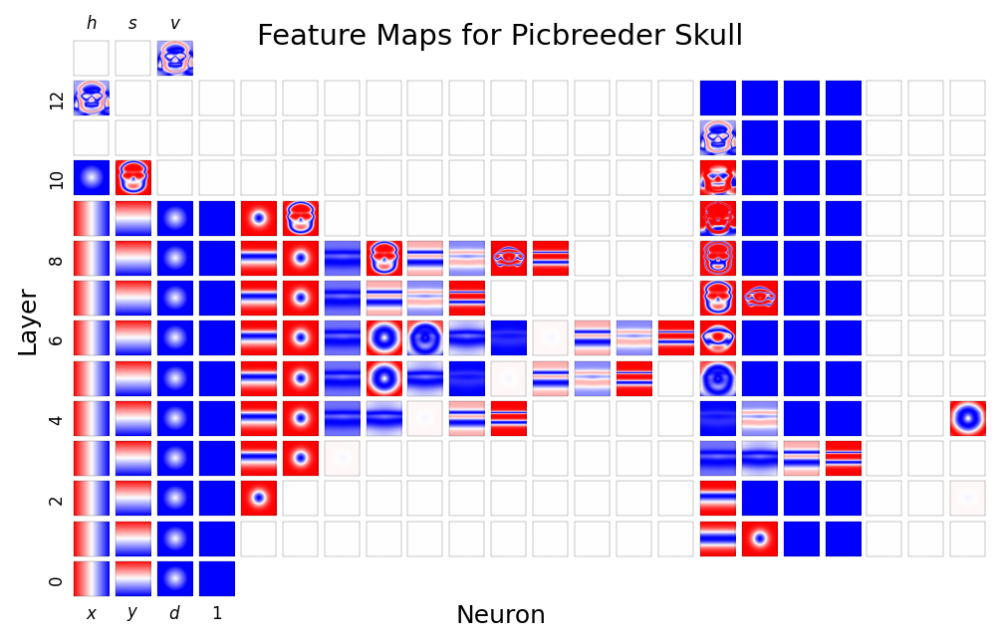

ParameterReshaper: 5478 parameters detected for optimization.


  0%|          | 0/14 [00:00<?, ?it/s]

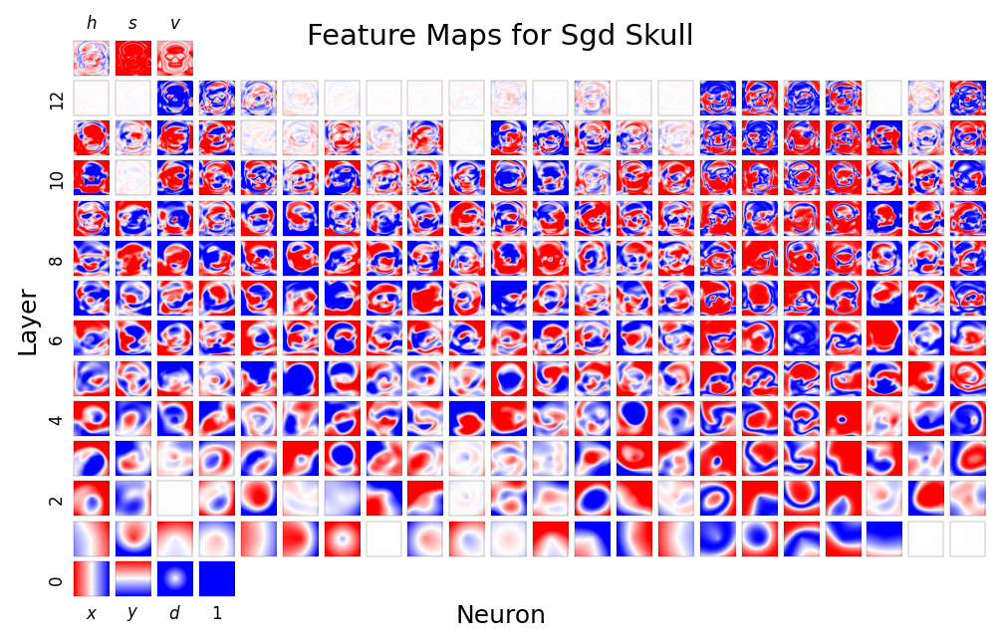

ParameterReshaper: 8096 parameters detected for optimization.


  0%|          | 0/18 [00:00<?, ?it/s]

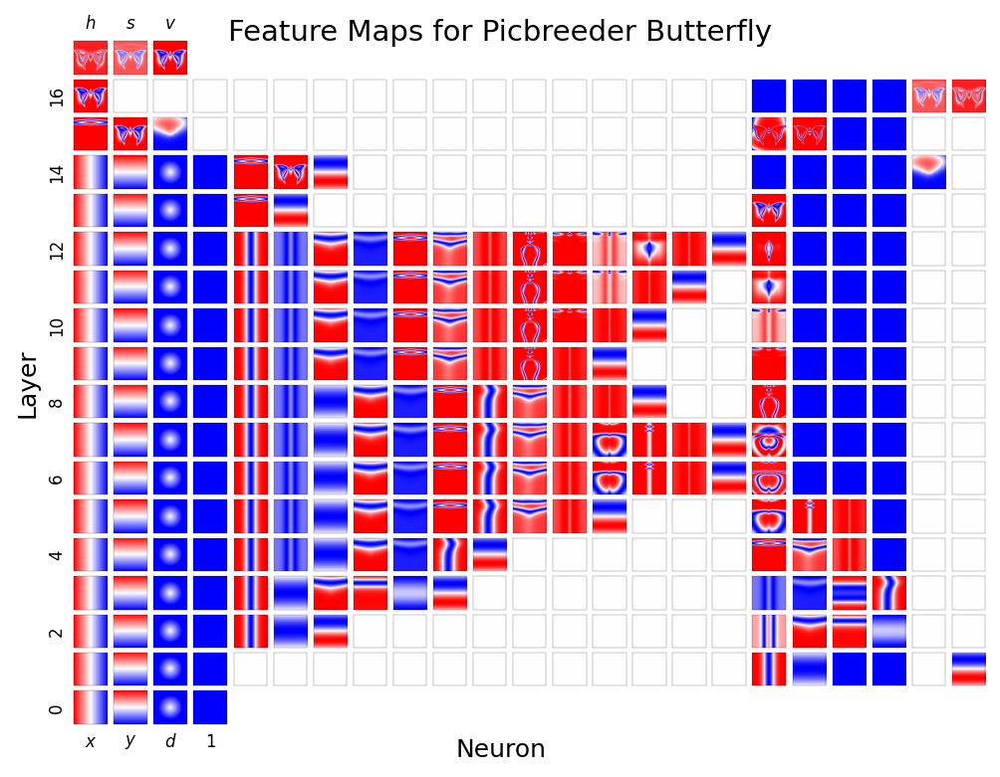

ParameterReshaper: 8096 parameters detected for optimization.


  0%|          | 0/18 [00:00<?, ?it/s]

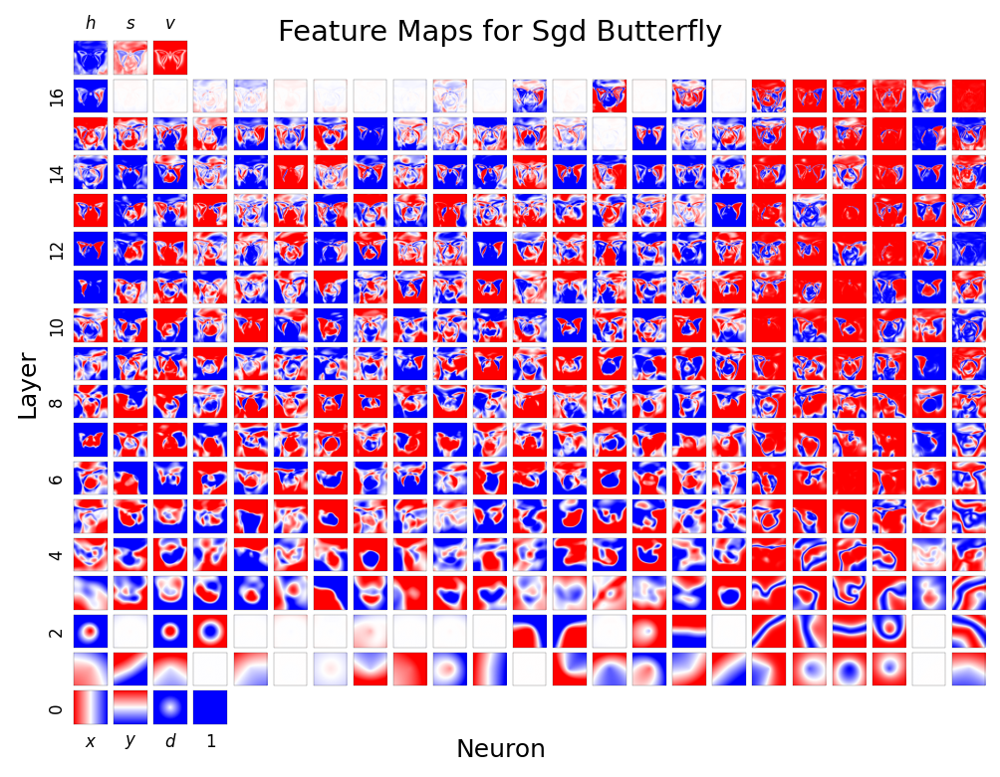

ParameterReshaper: 46474 parameters detected for optimization.


  0%|          | 0/35 [00:00<?, ?it/s]

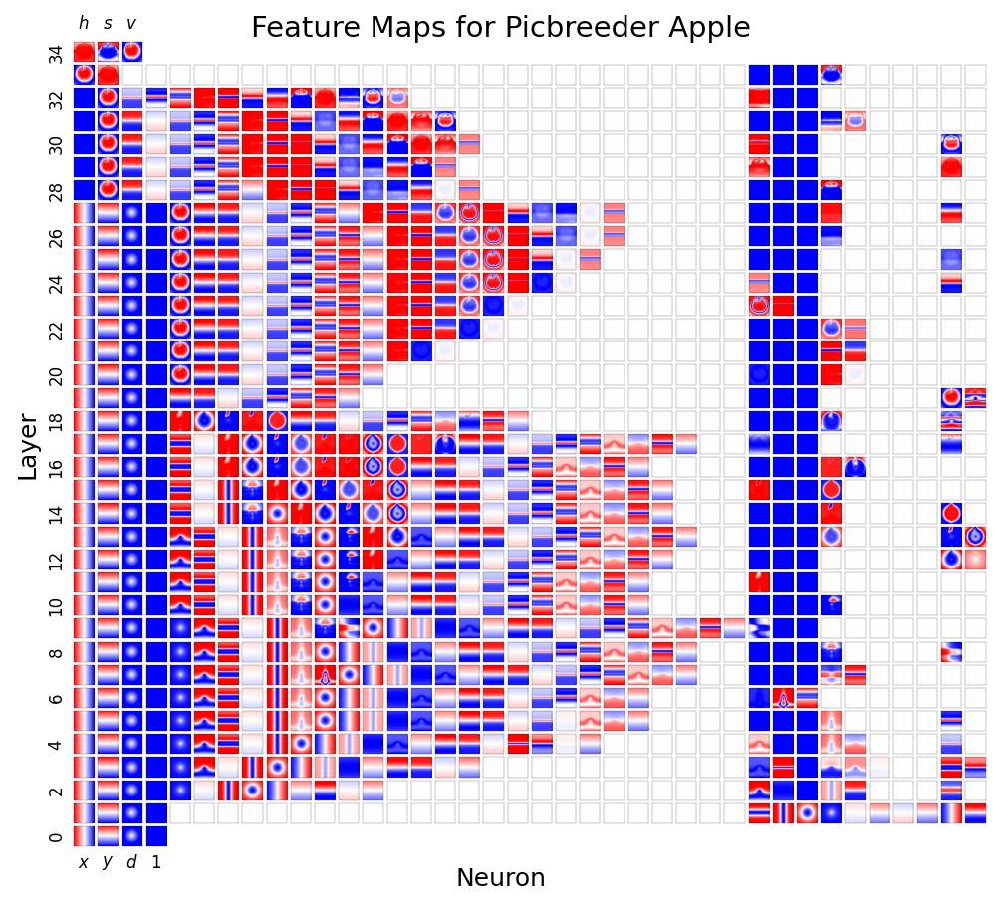

ParameterReshaper: 46474 parameters detected for optimization.


  0%|          | 0/35 [00:00<?, ?it/s]

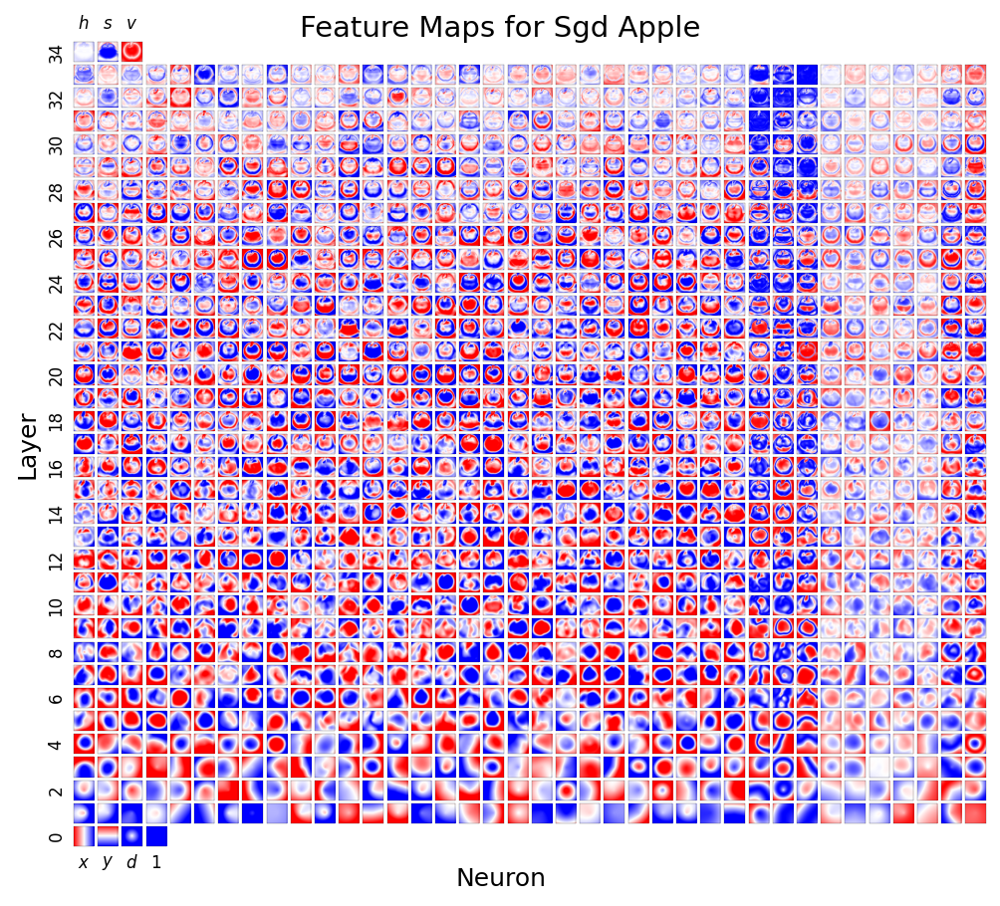

In [9]:
for genome in ["skull", "butterfly", "apple"]:
    for source in ["picbreeder", "sgd"]:
        save_dir = f"../data/{source}_{genome}"
        arch_ = util.load_pkl(save_dir, "arch")
        params = util.load_pkl(save_dir, "params")
        cppn = FlattenCPPNParameters(CPPN(arch_))
        img, features = cppn.generate_image(params, img_size=128, return_features=True)
        features = jax.tree.map(lambda x: np.array(x), features)
        fig = viz_feature_maps(features)
        plt.suptitle(f"Feature Maps for {source.capitalize()} {genome.capitalize()}", fontsize=14)
        plt.show()

Notice that although the Picbreeder and SGD CPPNs have the same output behavior, their internal representations are extremely different.
Picbreeder representation is **Unified and Factored** while the SGD representation is **Fractured and Entangled**.

# Weight Sweeps
Here, we will sweep individual weights across a suite of values to see how that single weight affects the output image.
Because the parameters of the network are flat vectors (thanks to FlattenCPPNParameters), this is pretty easy to do.

Feel free to play around with different weight sweeps yourself for the Picbreeder and SGD CPPNs!

In [10]:
def sweep_weight(params, weight_id, cppn, img_size=256, center_weight=None, r=1, n=5):
    """
    Sweeps a single weight across a range of values.
    params: the parameters of the network as a flat vector
    weight_id: the index of the weight to sweep
    cppn: the CPPN object
    img_size: the size of the image to generate
    center_weight: center the sweep around this weight value, None for original weight value
    r: the distance to sweep the weight (-r, r)
    n: the number of samples to take between -r and r
    """
    assert (center_weight is None) or isinstance(center_weight, float)
    weight_sweep = jnp.linspace(-r, r, n)
    if isinstance(center_weight, float):
        weight_sweep = weight_sweep + center_weight
    else:
        weight_sweep = weight_sweep + params[weight_id]
    params_p = repeat(params, "p -> n p", n=n).at[:, weight_id].set(weight_sweep)
    # imgs = gen_img_fn(params_p)
    imgs = jax.vmap(partial(cppn.generate_image, img_size=img_size))(params_p)
    return imgs

ParameterReshaper: 5478 parameters detected for optimization.


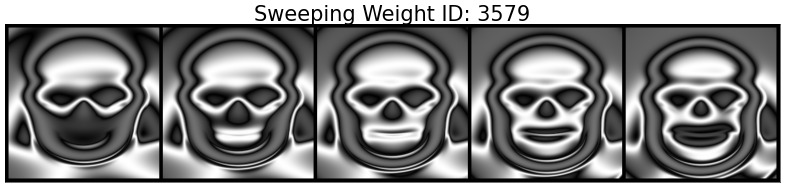

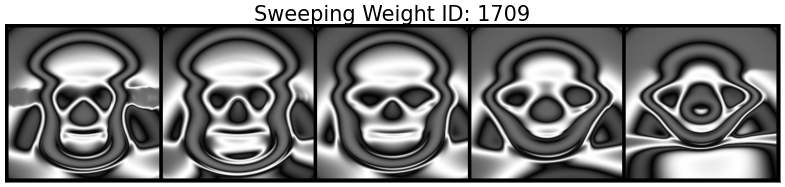

In [11]:
source, genome = "picbreeder", "skull" # changing source to "sgd" will sweep the SGD CPPNs, try it
save_dir = f"../data/{source}_{genome}"
arch_ = util.load_pkl(save_dir, "arch")
params = util.load_pkl(save_dir, "params")
cppn = FlattenCPPNParameters(CPPN(arch_))

sweep_weight_fn = partial(sweep_weight, cppn=cppn, img_size=256, center_weight=None, r=1, n=5)

padding = 6
for weight_id in [3579, 1709]:
    img = np.array(sweep_weight_fn(params, weight_id))
    img = np.pad(img, ((0, 0), (padding, 0), (padding, 0), (0, 0)), mode='constant', constant_values=0.)
    img = rearrange(img, "N H W D -> H (N W) D")
    img = np.pad(img, ((0, padding), (0, padding), (0, 0)), mode='constant', constant_values=0.)

    plt.figure(figsize=(20, 5), dpi=50)
    plt.imshow(img)
    plt.xticks([]); plt.yticks([]); plt.grid(False)
    plt.title(f"Sweeping Weight ID: {weight_id}", fontsize=30)
    plt.show()


Here is the code to replicate the original sweeps from the paper.

In [12]:
weight_sweep_data = {}

weight_ids = [4371, 5009, 5097, 37]
descriptions = ["Controls Mouth Opening", "Controls Eye Winking", "Controls Eye Width", "Controls Jaw Width"]
weight_sweep_controls = [None, None, None, None]
weight_sweep_data[("picbreeder", "skull")] = dict(weight_ids=weight_ids, descriptions=descriptions, weight_sweep_controls=weight_sweep_controls)

weight_ids = [1587, 81, 46, 3185]
descriptions = [" ", " ", " ", " "]
weight_sweep_controls = [None, None, None, None]
weight_sweep_data[("sgd", "skull")] = dict(weight_ids=weight_ids, descriptions=descriptions, weight_sweep_controls=weight_sweep_controls)


weight_ids = [1949, 3702, 17, 133]
descriptions = ["Controls Wing Area", "Controls Color", "Converts Butterfly to Fly", "Controls Vertical Shape"]
weight_sweep_controls = [None, None, None, None]
weight_sweep_data[("picbreeder", "butterfly")] = dict(weight_ids=weight_ids, descriptions=descriptions, weight_sweep_controls=weight_sweep_controls)

weight_ids = [5603, 3796, 3848, 78 ]
descriptions = [" ", " ", " ", " "]
weight_sweep_controls = [None, None, None, None]
weight_sweep_data[("sgd", "butterfly")] = dict(weight_ids=weight_ids, descriptions=descriptions, weight_sweep_controls=weight_sweep_controls)


weight_ids = [42178, 4140, 34459, 17131]
descriptions = ["Controls Stem Angle", "Controls Apple Size", "Cleans Background", "Removes Stem"]
weight_sweep_controls = [(-1., 2.), None, None, None]
weight_sweep_data[("picbreeder", "apple")] = dict(weight_ids=weight_ids, descriptions=descriptions, weight_sweep_controls=weight_sweep_controls)

weight_ids = [37753, 135, 37721, 37809]
descriptions = [" ", r"$\approx$ Controls Apple Size", r"$\approx$ Cleans Background", " "]
weight_sweep_controls = [None, None, None, None]
weight_sweep_data[("sgd", "apple")] = dict(weight_ids=weight_ids, descriptions=descriptions, weight_sweep_controls=weight_sweep_controls)


ParameterReshaper: 5478 parameters detected for optimization.


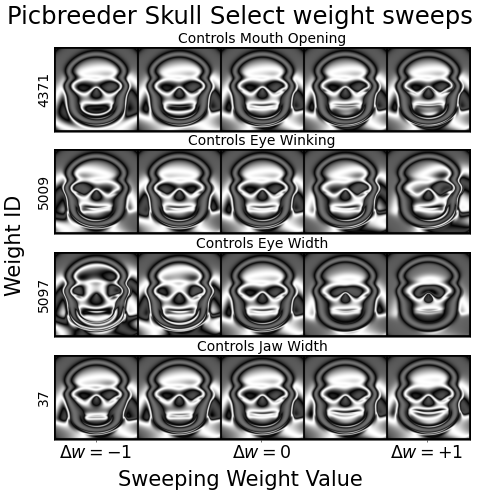

ParameterReshaper: 5478 parameters detected for optimization.


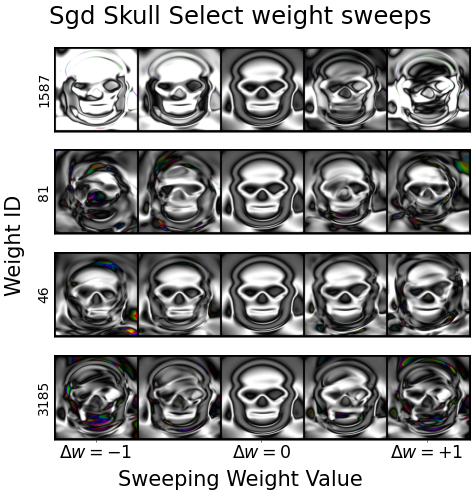

ParameterReshaper: 8096 parameters detected for optimization.


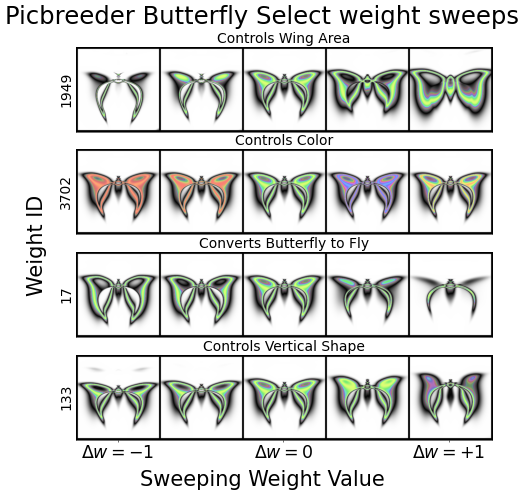

ParameterReshaper: 8096 parameters detected for optimization.


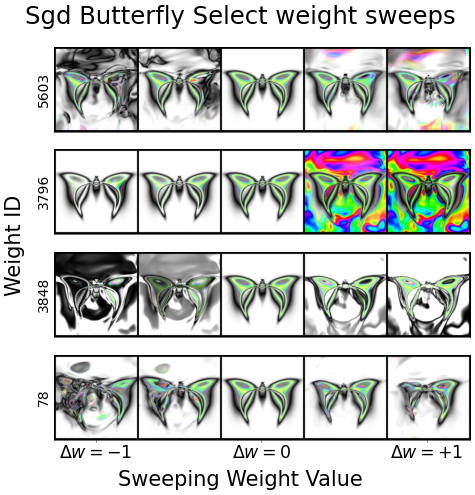

ParameterReshaper: 46474 parameters detected for optimization.


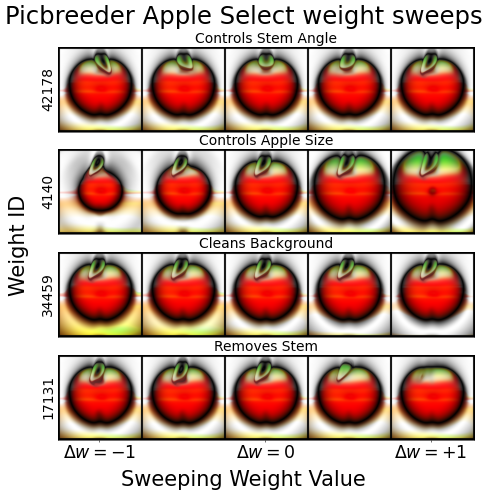

ParameterReshaper: 46474 parameters detected for optimization.


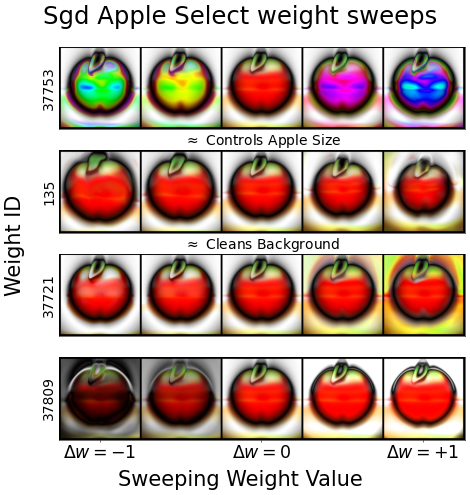

In [13]:
for genome in ["skull", "butterfly", "apple"]:
    for source in ["picbreeder", "sgd"]:
        save_dir = f"../data/{source}_{genome}"
        arch_ = util.load_pkl(save_dir, "arch")
        params = util.load_pkl(save_dir, "params")
        cppn = FlattenCPPNParameters(CPPN(arch_))
        # sweep_weight_fn = partial(sweep_weight_random_direction, cppn=cppn, img_size=64, center_weight=None, r=1, n=5, ret="imgs")

        data = weight_sweep_data[(source, genome)]
        
        fig, axs = plt.subplots(4, 1, figsize=(10, 10), dpi=50)
        padding = 6
        for iplt, (weight_id, controls, description) in enumerate(zip(data["weight_ids"], data["weight_sweep_controls"], data["descriptions"])):
            if controls is None:
                sweep_weight_fn = partial(sweep_weight, cppn=cppn, img_size=256, center_weight=None, r=1, n=5)
            else:
                c, r = controls
                sweep_weight_fn = partial(sweep_weight, cppn=cppn, img_size=256, center_weight=c, r=r, n=5)


            img = np.array(sweep_weight_fn(params, weight_id))

            img = np.pad(img, ((0, 0), (padding, 0), (padding, 0), (0, 0)), mode='constant', constant_values=0.)
            img = rearrange(img, "N H W D -> H (N W) D")
            img = np.pad(img, ((0, padding), (0, padding), (0, 0)), mode='constant', constant_values=0.)

            plt.sca(axs[iplt])
            plt.imshow(img)
            plt.xticks([]); plt.yticks([]); plt.grid(False)
            plt.title(f"{description}", fontsize=20)
            plt.ylabel(f"{weight_id}", fontsize=20)
            if iplt==3:
                img_size_p = 256+padding
                plt.xticks([img_size_p*0+img_size_p/2, img_size_p*2+img_size_p/2, img_size_p*4+img_size_p/2], ["$\Delta w = -$1", "$\Delta w = $0", "$\Delta w = +$1"], fontsize=25)

        plt.gcf().supylabel("Weight ID", fontsize=30, x=0.03)
        plt.gcf().supxlabel("Sweeping Weight Value", fontsize=30)
        plt.suptitle(f"{source.capitalize()} {genome.capitalize()} Select weight sweeps", fontsize=35)
        plt.tight_layout()
        # plt.savefig(f"/home/akarsh_sakana_ai/spaghetti-data/figures/weight_sweeps_{pid}_{arch}.pdf", format="pdf", bbox_inches="tight", dpi=300)
        # plt.close()
        plt.show()



Now let's do some sweeps which are agnostic to the basis of the feature's vector space, so we aren't assuming that the neuron basis is the only one that matters.
See paper appendix for more details.

In [14]:

def sweep_weight_random_direction(params, seed, cppn, img_size=256, center_weight=None, r=1, n=5):
    """
    Sweeps a column of the weight matrix in a random direction.
    The reason we do this is to create weight sweeps that are agnostic to any particular basis of the resulting feature's vector space.
    For more details, see the paper appendix.
    """
    assert (center_weight is None) or isinstance(center_weight, float)
    params = cppn.param_reshaper.reshape_single(params)
    layer_names = list(params['params'].keys())
    rng1, rng2 = jax.random.split(jax.random.PRNGKey(seed), 2)
    # layer_idx = jax.random.choice(rng1, len(layer_names)).item()
    # layer_name = layer_names[layer_idx]
    np.random.seed(seed)
    layer_name = np.random.choice(layer_names)
    n_rows, n_cols = params['params'][layer_name]['kernel'].shape
    i_row = jax.random.randint(rng1, (), 0, n_rows)
    e_i = jnp.eye(n_rows)[i_row]
    vec = jax.random.normal(rng2, (n_cols,))
    vec = vec/jnp.linalg.norm(vec)
    dW = e_i[:, None] @ vec[None, :]
    ts = jnp.linspace(-r, r, n)
    def gen_single_t(t):
        p = jax.tree.map(lambda x: x, params)
        p['params'][layer_name]['kernel'] = p['params'][layer_name]['kernel'] + t*dW
        p = cppn.param_reshaper.flatten_single(p)
        img = cppn.generate_image(p, img_size=img_size)
        return img
    imgs = jax.vmap(gen_single_t)(ts)
    return imgs


In [15]:
rand_weight_sweep_data = {}
for source in ["picbreeder", "sgd"]:
    for genome in ["skull", "butterfly", "apple"]:
        save_dir = f"../data/{source}_{genome}"
        arch_ = util.load_pkl(save_dir, "arch")
        params = util.load_pkl(save_dir, "params")
        cppn = FlattenCPPNParameters(CPPN(arch_))

        sweep_weight_fn = partial(sweep_weight_random_direction, cppn=cppn, img_size=64, center_weight=None, r=1, n=5)
        imgs = np.stack([sweep_weight_fn(params, seed) for seed in tqdm(range(200))])
        imgs = imgs[imgs.var(axis=1).mean(axis=(-1, -2, -3)).argsort()[::-1]] # sort by highest to lowest variance
        rand_weight_sweep_data[(source, genome)] = imgs

ParameterReshaper: 5478 parameters detected for optimization.


  0%|          | 0/200 [00:00<?, ?it/s]

ParameterReshaper: 8096 parameters detected for optimization.


  0%|          | 0/200 [00:00<?, ?it/s]

ParameterReshaper: 46474 parameters detected for optimization.


  0%|          | 0/200 [00:00<?, ?it/s]

... (2 outputs left out)

ParameterReshaper: 8096 parameters detected for optimization.


  0%|          | 0/200 [00:00<?, ?it/s]

ParameterReshaper: 46474 parameters detected for optimization.


  0%|          | 0/200 [00:00<?, ?it/s]

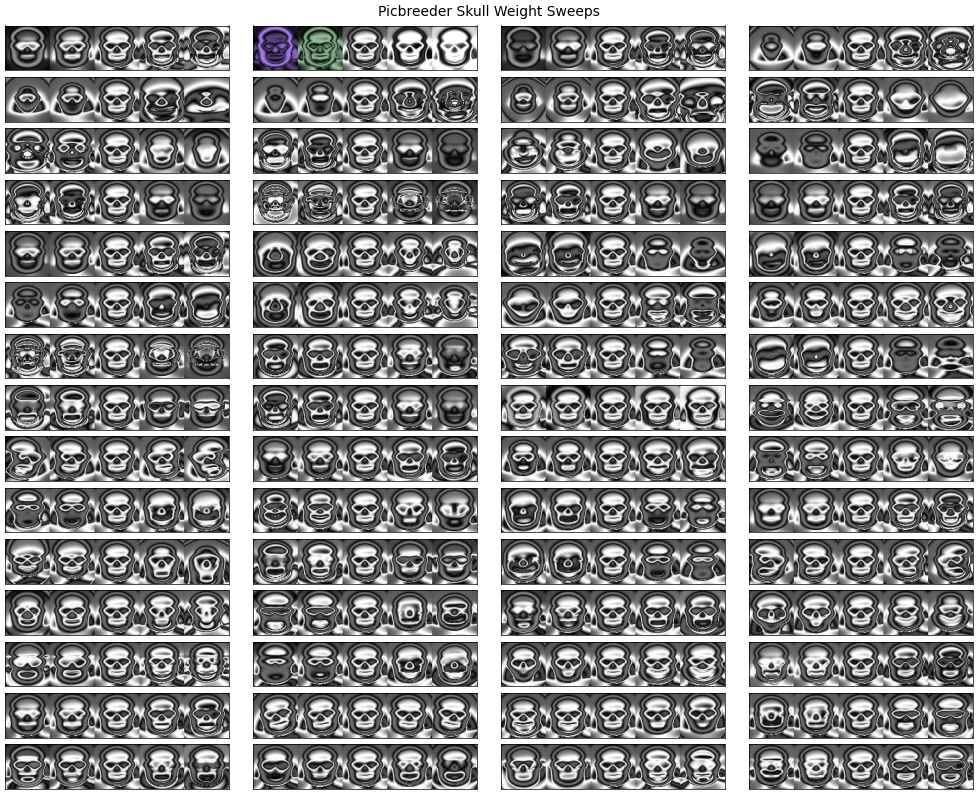

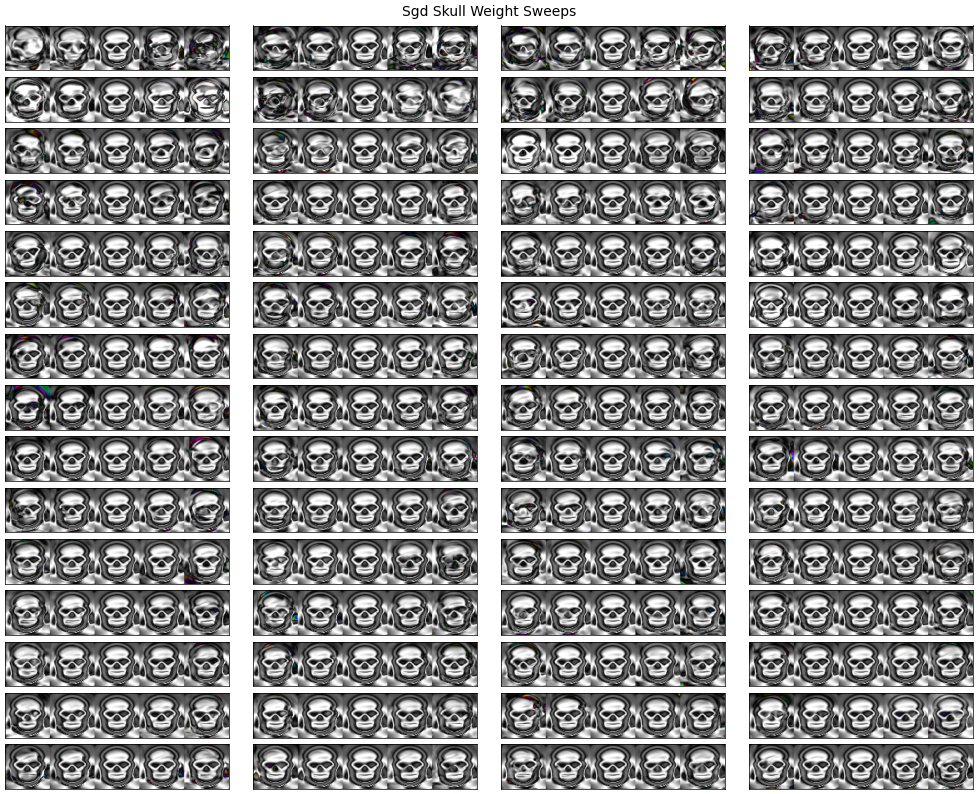

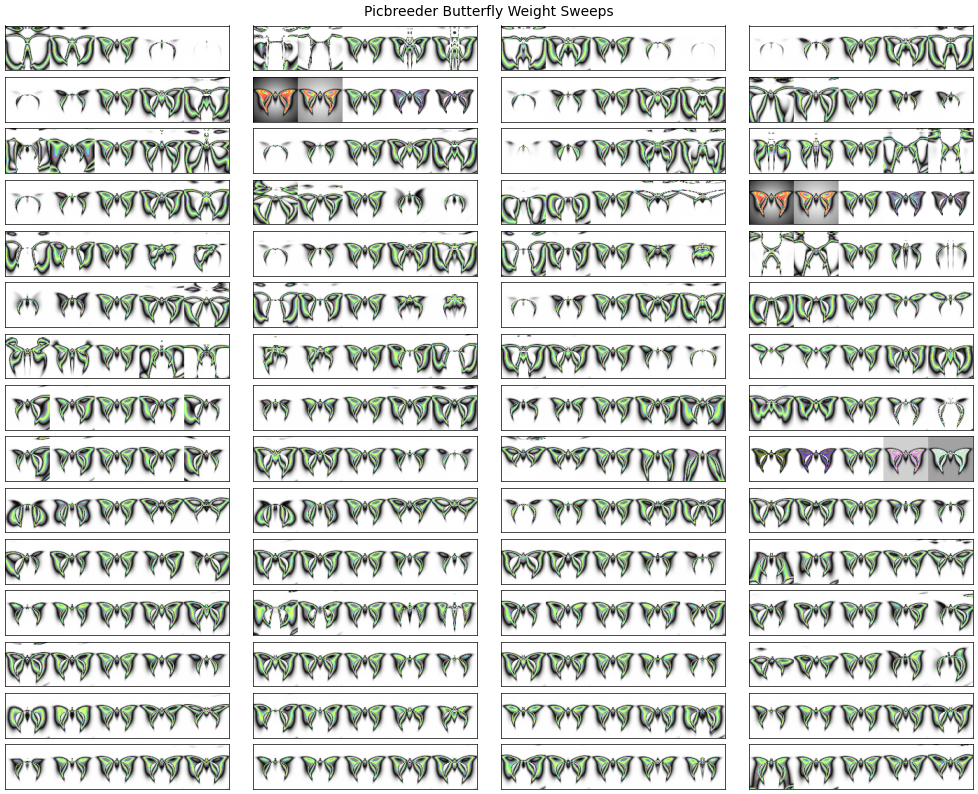

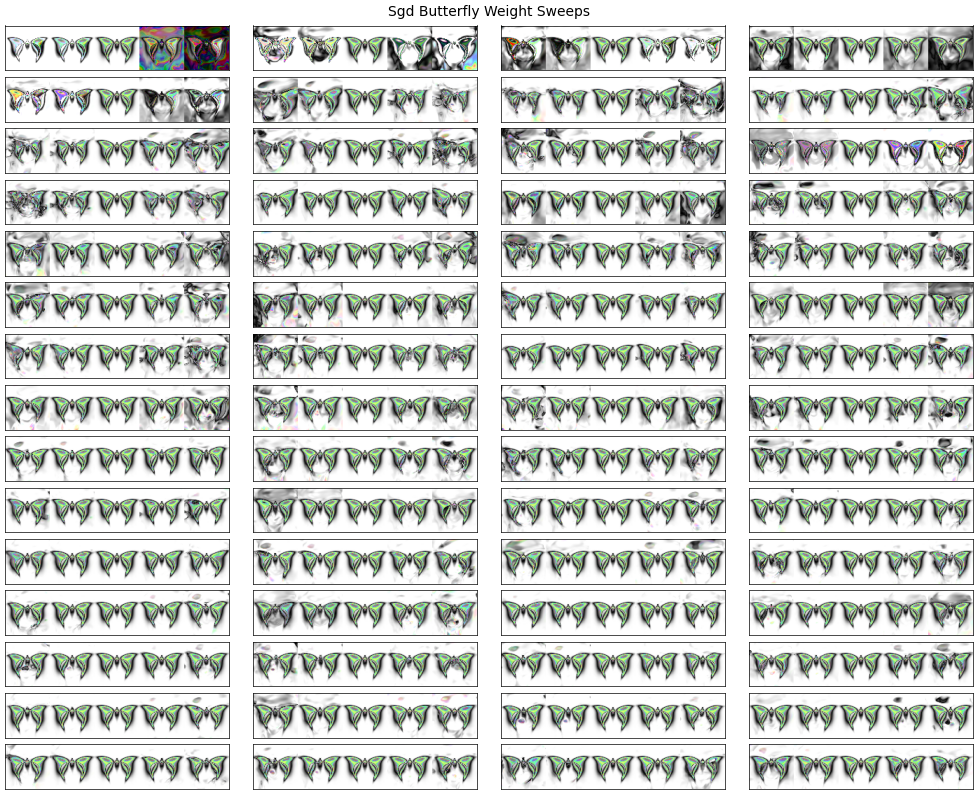

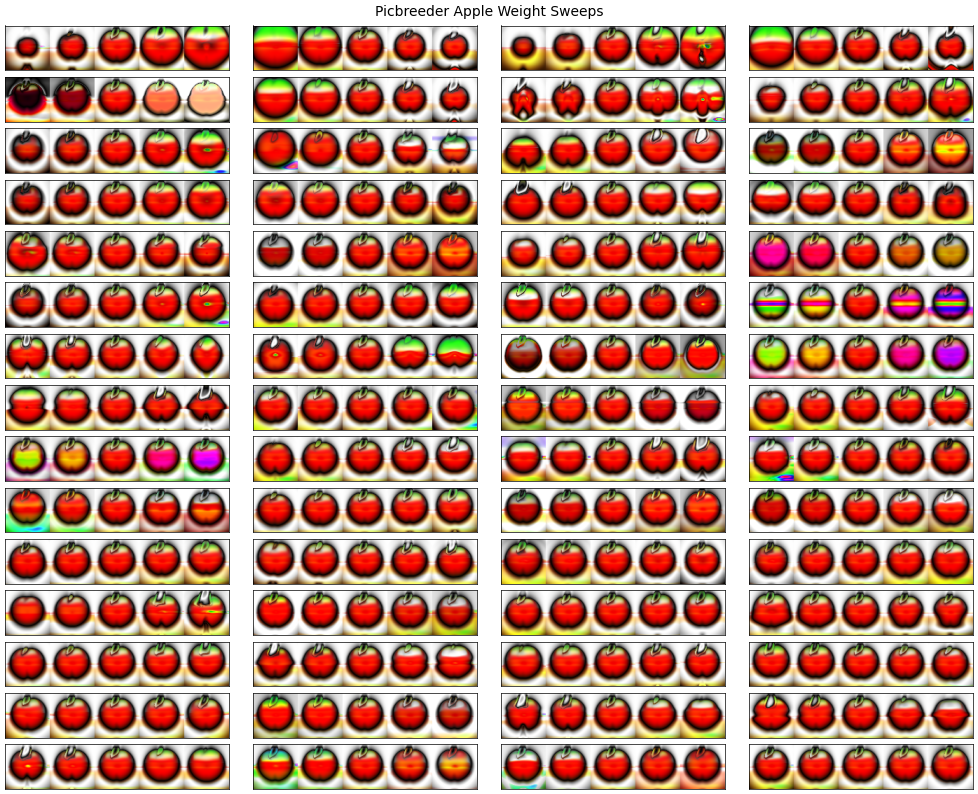

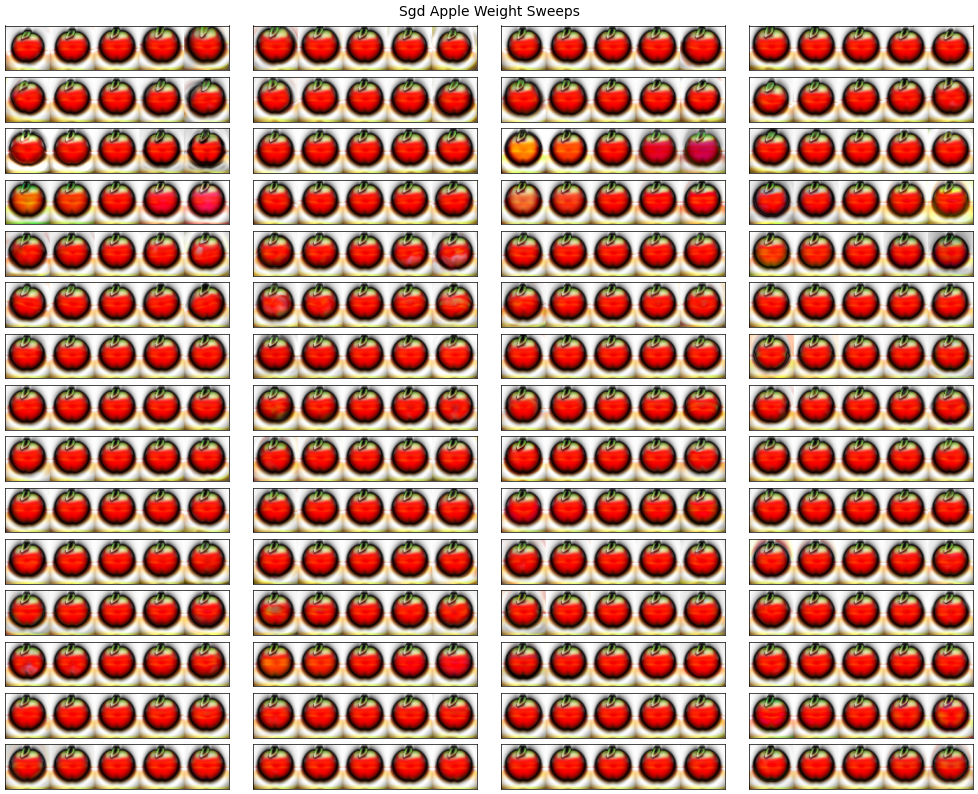

In [16]:
for genome in ['skull', 'butterfly', 'apple']:
    for source in ['picbreeder', 'sgd']:
        plt.figure(figsize=(20, 16), dpi=50)
        for i in range(60):
            img = rand_weight_sweep_data[(source, genome)][i]
            img = rearrange(img, "T H W D -> H (T W) D")
            plt.subplot(15, 4, i+1)
            plt.imshow(img); plt.xticks([]); plt.yticks([]); plt.grid(False)
            for spine in plt.gca().spines.values():
                spine.set_edgecolor('black')
                spine.set_linewidth(1)
        plt.suptitle(f"{source.capitalize()} {genome.capitalize()} Weight Sweeps", fontsize=20, y=0.99)
        plt.tight_layout()
        plt.show()